In [1]:
import warnings
import pandas as pd
import plotly.express as px
from data import *

warnings.filterwarnings("ignore")
pd.set_option('display.max_rows', None)

:: loading settings :: url = jar:file:/home/daniel.las/work/workspace-crypto/warehouse/jupyterlab/venv/lib/python3.8/site-packages/pyspark/jars/ivy-2.5.0.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/daniel.las/.ivy2/cache
The jars for the packages stored in: /home/daniel.las/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
org.apache.spark#spark-avro_2.12 added as a dependency
org.postgresql#postgresql added as a dependency
com.github.jnr#jnr-posix added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-3d31481b-a2cc-4fe5-a54a-84fa89b61c6b;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.2.0 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.2.0 in central
	found com.datastax.oss#java-driver-core-shaded;4.13.0 in central
	found com.datastax.oss#native-protocol;1.5.0 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in local-m2-cache
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhist

# Ilość zamkniętych zadań miesięcznie

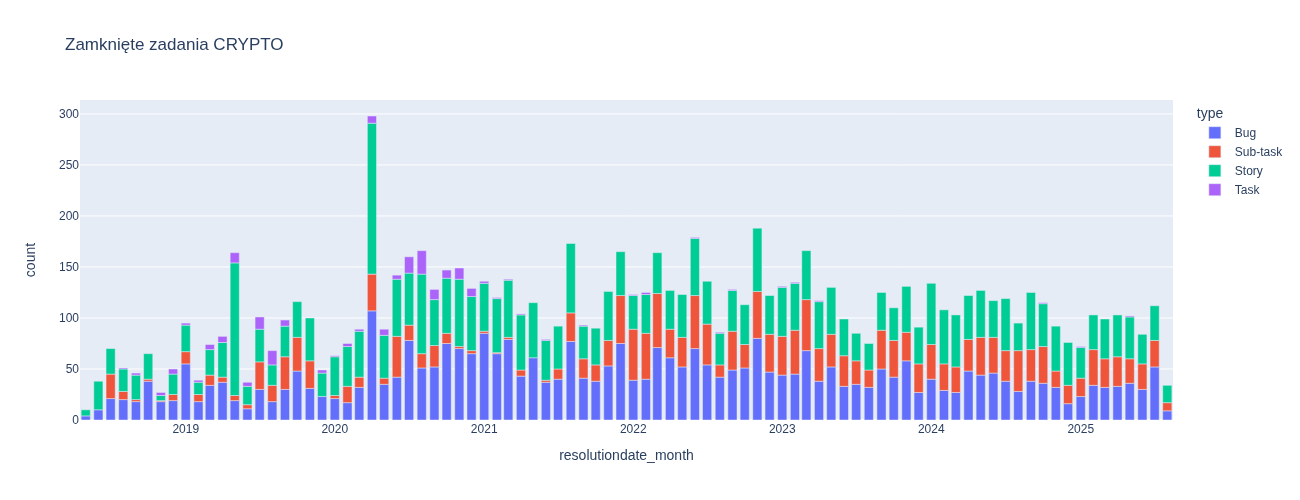

In [3]:
px.bar(
    issues_completed_by_month.where(f.col('project')=='CRYP').toPandas(),
    x='resolutiondate_month',
    y='count',
    color='type',
    title='Zamknięte zadania CRYPTO',
    height=500)

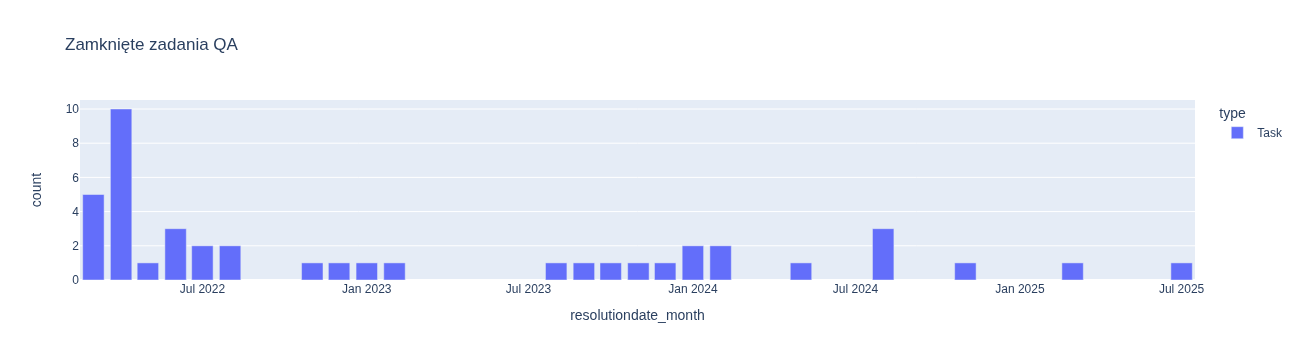

In [4]:
px.bar(
    issues_completed_by_month.where(f.col('project')=='QT').toPandas(),
    x='resolutiondate_month',
    y='count',
    color='type',
    title='Zamknięte zadania QA')

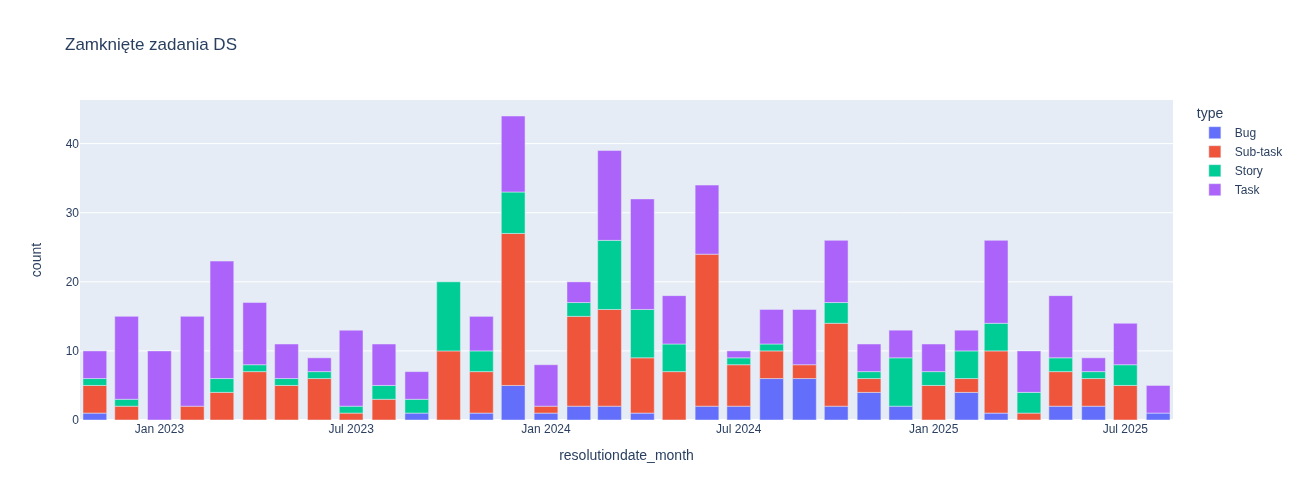

In [6]:
px.bar(
    issues_completed_by_month.where(f.col('project')=='DE').toPandas(),
    x='resolutiondate_month',
    y='count',
    color='type',
    title='Zamknięte zadania DS',
    height=500)

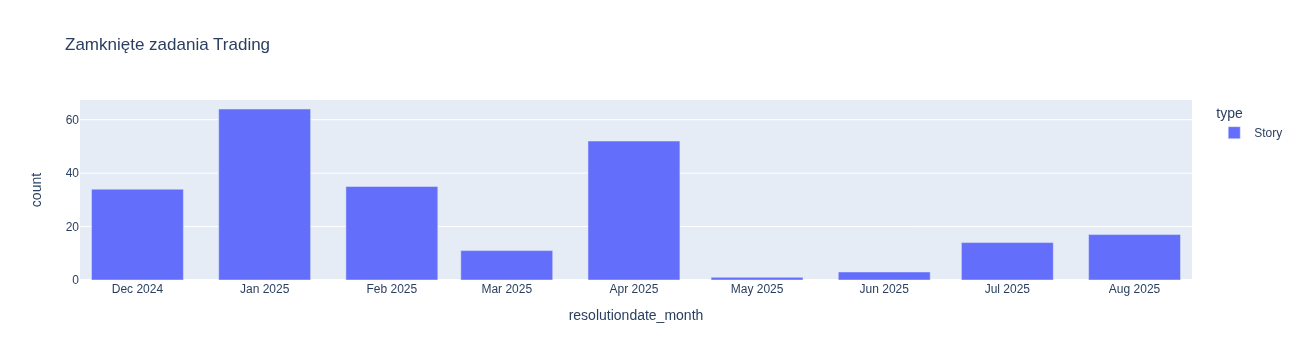

In [7]:
px.bar(
    issues_completed_by_month.where(f.col('project')=='TRAD').toPandas(),
    x='resolutiondate_month',
    y='count',
    color='type',
    title='Zamknięte zadania Trading')

# Aktywne długo trwające zadania 

In [8]:
from functions import filter_heavy_open_issues

work_hours_threshold = 40
skip_status = ['Backlog','Delivery','Delivered']

filter_heavy_open_issues(issues_open, ts, issues_hours, work_hours_threshold, skip_status)\
.toPandas()\
.groupby(['key','summary','type','priority','status','size','user'])\
.max(numeric_only = True)\
.sort_values(by=['issue_total_hours'],ascending=[False])

issue_total_hours  \
key        summary                                       type     priority status      size user                      
CRYP-10532 Cassandra Problemy z zasobami                 Story    Medium   In Review   XL   ATa               175.5   
                                                                                            MSo               175.5   
CRYP-9217  [WebTP] problemy z performance w webTP        Story    Medium   In Progress ?    PAn               163.5   
CRYP-10311 [Global position manager] Pierwsza wersja     Story    Medium   To Do       M    PGr                89.0   
CRYP-9716  [Wallet monitor] Proof of concept rozwiązania Sub-task Medium   In Progress M    MRy                73.0   
CRYP-10866 [AS] Stworzenie Arbitrage strategy            Story    High     In Progress ?    KBa                53.0   
                                                                                            MSo                53.0   
                                                                                            PGr                53.0   
CRYP-9753  [Platform Admin UI] Dodanie testów            Story    Medium   To Do       XS   PAn                45.0   
CRYP-8364  [WebTP] UI properties - refactor              Story    Medium   To Do       M    PAn                44.0   

                                                                                                  user_total_hours  
key        summary                                       type     priority status      size user                    
CRYP-10532 Cassandra Problemy z zasobami                 Story    Medium   In Review   XL   ATa              119.5  
                                                                                            MSo               56.0  
CRYP-9217  [WebTP] problemy z performance w webTP        Story    Medium   In Progress ?    PAn              163.5  
CRYP-10311 [Global position manager] Pierwsza wersja     Story    Medium   To Do       M    PGr               89.0  
CRYP-9716  [Wallet monitor] Proof of concept rozwiązania Sub-task Medium   In Progress M    MRy               73.0  
CRYP-10866 [AS] Stworzenie Arbitrage strategy            Story    High     In Progress ?    KBa               51.0  
                                                                                            MSo                1.0  
                                                                                            PGr                1.0  
CRYP-9753  [Platform Admin UI] Dodanie testów            Story    Medium   To Do       XS   PAn               45.0  
CRYP-8364  [WebTP] UI properties - refactor              Story    Medium   To Do       M    PAn               44.0

# Ilość zmergowanych merge requestów miesięcznie

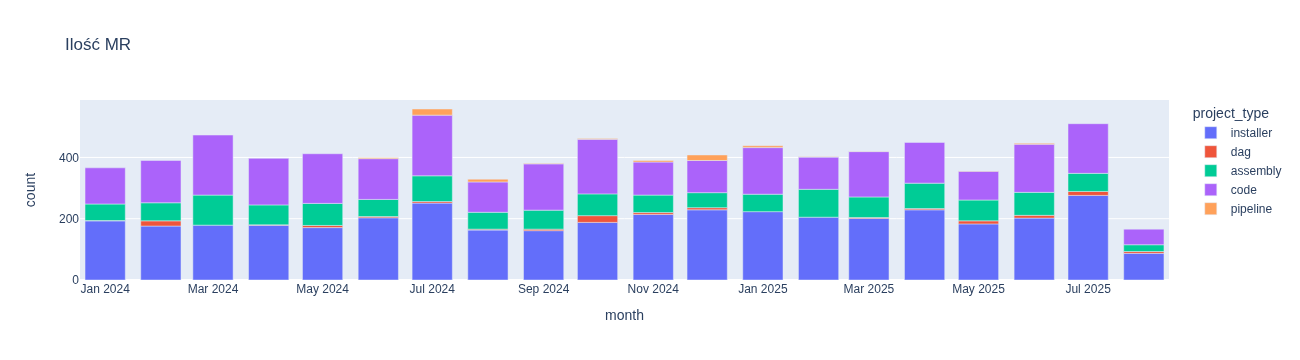

In [9]:
px.bar(mrs_count_by_type.toPandas(),x='month',y='count',color='project_type',title='Ilość MR')

# Czas trwania merge requestów

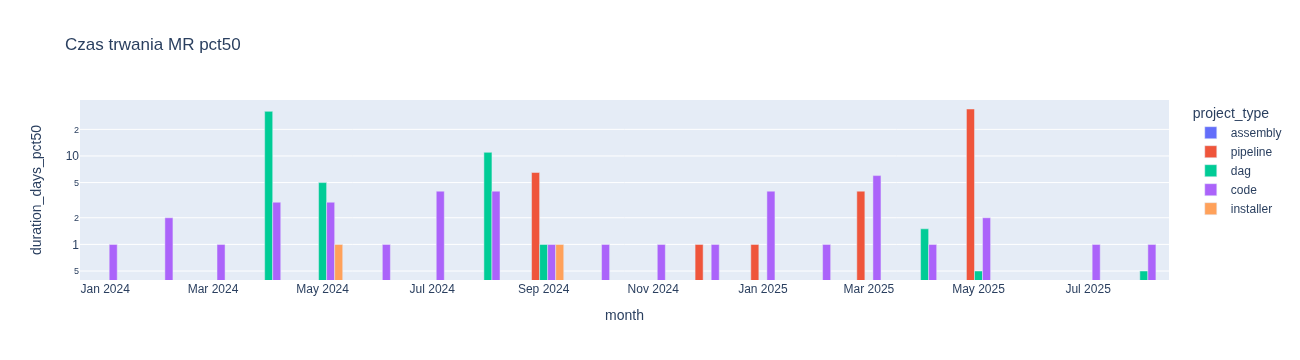

In [10]:
px.bar(mrs_duration.toPandas(),x='month',y='duration_days_pct50',color='project_type',title='Czas trwania MR pct50',log_y=True,barmode='group')

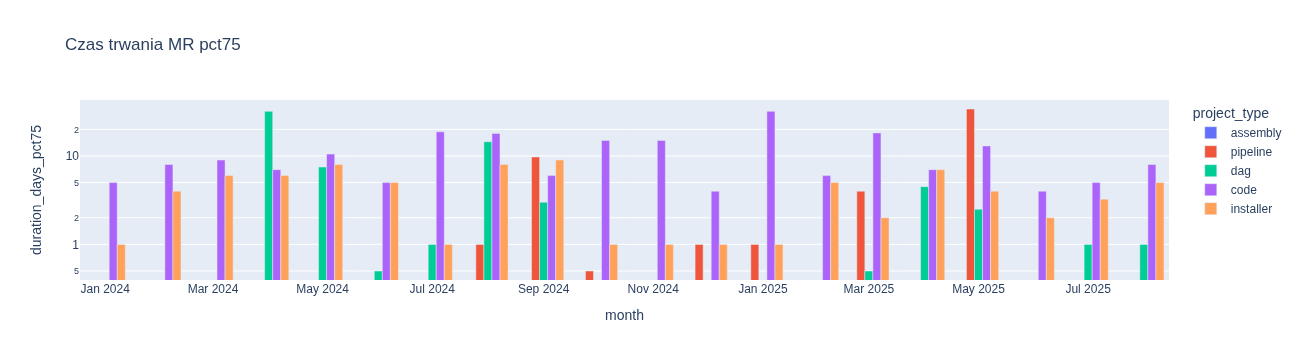

In [11]:
px.bar(mrs_duration.toPandas(),x='month',y='duration_days_pct75',color='project_type',title='Czas trwania MR pct75',log_y=True,barmode='group')

# Ilość komentarzy do merge requestów

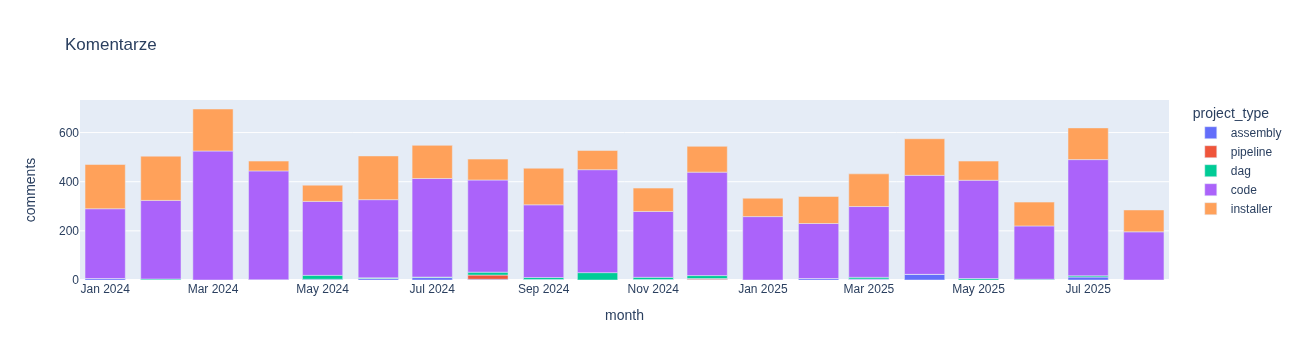

In [12]:
px.bar(mrs_comments.toPandas(),x='month',y='comments',color='project_type',title='Komentarze')

# Statystyki commitów

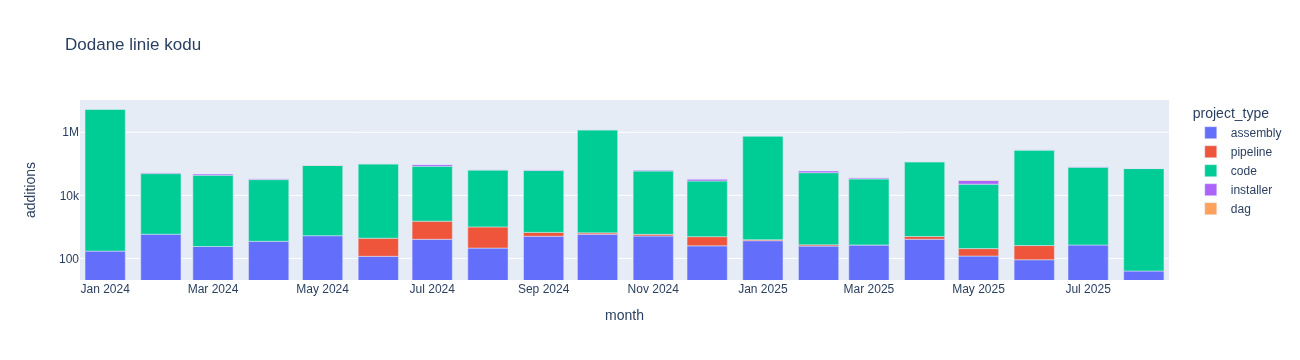

In [13]:
px.bar(commits_by_project_type.toPandas(),x='month',y='additions',color='project_type',title='Dodane linie kodu',log_y=True)

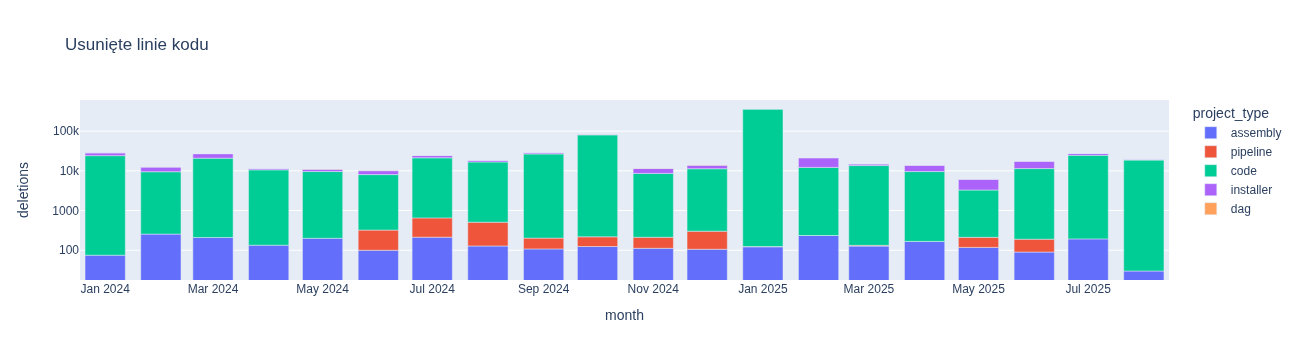

In [14]:
px.bar(commits_by_project_type.toPandas(),x='month',y='deletions',color='project_type',title='Usunięte linie kodu',log_y=True)

# Zadania Algo bez estymat

In [15]:
issues_normalized \
.join(ts, ts.jira_id == issues_normalized.key, 'left')\
.join(issues_hours, issues_hours.key == issues_normalized.key)\
.where(issues_normalized.project == 'CRYP')\
.where(f.col('status_changed_at') > past_date(180))\
.where(f.col('size') == '?')\
.where(~f.col('user').isin(['CWr','MDe']))\
.groupBy(
    issues_normalized.key,
    f.col('summary'),
    f.col('status'),
    f.col('type'),
    f.col('status_changed_at'),
    f.col('user'))\
.agg(f.sum('hours').alias('user_total_hours'))\
.orderBy(f.col('status_changed_at').desc())\
.toPandas()\
.groupby(by=['key','summary','status','type','status_changed_at','user'])\
.max()\
.sort_values(by='status_changed_at',ascending=False)

user_total_hours
key        summary                                            status        type     status_changed_at       user                  
CRYP-11006 [Backtest]Nie utworzyly się konfiguracje dla po... Ready to test Bug      2025-08-13 13:26:40.460 DLa               3.50
CRYP-10826 [platform admin] Stworzenie formularza dla rozs... Done          Story    2025-08-13 11:47:47.857 PAn              18.00
CRYP-10874 [platform admin] Redirect na  Login page przy b... Done          Story    2025-08-13 11:47:46.045 PAn               2.00
CRYP-10949 [Bitkub] Zlecenie zostało w stanie 'pending new'   In testing    Bug      2025-08-13 08:03:09.545 PKo               2.00
CRYP-11015 [Volleyball] Zmiana rozstawienia zleceń na pozi... In Progress   Story    2025-08-13 05:59:36.756 PGr               3.00
CRYP-10879 [MDR] Bundle marker-data-recorder za wcześnie (... In Progress   Bug      2025-08-12 13:50:36.420 MRy               0.50
CRYP-10965 [gate.io futures] Opóźniony restart po braku zd... In Review     Bug      2025-08-12 13:50:25.822 MRy               4.00
CRYP-10964 Naprawa TWCS liquee_liquidity                      In Progress   Story    2025-08-12 10:02:02.947 DLa               1.50
                                                                                                             MSo               4.00
CRYP-10984 Brak alertów kafka-sink                            Delivered     Bug      2025-08-12 07:35:57.938 ATa               4.00
CRYP-10845 Klaster Spark pod kontrolą Hadoop                  In Progress   Story    2025-08-12 07:35:26.460 ATa               9.50
CRYP-10933 [Volleyball] Zła obsługa raportów Expired          Closed        Bug      2025-08-12 05:51:28.536 PGr               7.50
CRYP-10994 [recording-log-migrator] Przeniesienie do java ... In Review     Sub-task 2025-08-11 14:23:21.962 TGa               9.00
CRYP-10922 [gate.io futures] ConnectTimeoutException          Delivery      Bug      2025-08-11 12:35:18.110 PKo               0.50
CRYP-11008 Błędy migracji AMM_DATA                            To Do         Bug      2025-08-11 12:07:44.585 DLa               3.50
CRYP-10861 [Infrastructure-installer] Playbook ca failuje ... Delivered     Story    2025-08-08 11:10:12.666 MSo               2.50
CRYP-10735 Zbędne alerty FeedAdapterDown dla adapterów fee... In Progress   Story    2025-08-07 08:20:56.945 MSo               2.00
CRYP-10986 Archiver HDFS nie może odnaleźć serwera InfluxDB   Delivered     Bug      2025-08-07 08:07:11.846 MSo               3.50
CRYP-10957 [Shift analyser] shift-analysis-reports dodanie... Done          Story    2025-08-07 07:54:59.895 DLa               5.00
CRYP-10982 [Backtest] Skrypt backtest_automation_manual dl... Invalid       Bug      2025-08-07 05:03:53.691 DLa               2.00
CRYP-10995 Usunięcie kontenera market data emitter Huobi p... Delivered     Story    2025-08-05 13:16:54.649 MSo               1.50
CRYP-10740 Dodanie mały hostów dla roli swarm manager         In Review     Story    2025-08-05 11:26:13.816 ATa              21.00
CRYP-10993 [Wallet-balance-migrator] Przeniesienie do java... In Progress   Sub-task 2025-08-05 08:12:38.600 TGa               6.00
CRYP-10950 [platform admin] Odświeżanie subskrypcji MDR - ... In Review     Story    2025-08-05 06:26:08.478 PAn              33.00
CRYP-10734 Zbieranie logów z fail2ban i OpenVPN do Grayloga   Delivered     Story    2025-08-04 12:48:19.513 ATa              22.50
CRYP-10800 Hdfs, kończy się miejsce. Analiza i naprawa.       Delivered     Story    2025-08-04 12:47:57.689 ATa               4.50
CRYP-10087 Automatyczna instalacja nowych hostów              Delivered     Story    2025-08-04 11:56:06.342 MSo              30.00
CRYP-10978 [Volleyball] Błędne mapowanie PartiallyFilled n... Delivery      Bug      2025-08-04 11:48:19.236 PKo               3.50
CRYP-10985 Migration verifier nie może odnaleźć serwera In... Delivered     Bug      2025-08-04 08:34:49.817 MSo               1.50
CRYP-10834 HDFS. Sprawd